# nb03 — Cluster characterization and tentative cell-state review
**Question:** What distinguishes the RNA clusters within MCF7 and T47D?
Review cluster quality, markers, sensitivity and descriptive gene-program scores.
This is exploratory characterization of the existing nb02 clusters.
Cluster-marker p-values are descriptive: clusters and markers use the same data,
cells are not independent biological replicates, and treatment composition may drive markers.
No E2-versus-Vehicle DEG analysis or GSEA is performed here; those belong in nb04.

## 1. Mount Drive and locate nb02 outputs

In [1]:
try:
    from google.colab import drive
except ImportError:
    IN_COLAB=False
else:
    IN_COLAB=True
    drive.mount('/content/drive')
import os
from pathlib import Path
BASE=Path('/content/drive/MyDrive/breast-cancer-multiome-estrogen') if IN_COLAB else Path(os.environ.get('MULTIOME_PROJECT_ROOT',Path.cwd())).resolve()
if BASE.name=='notebooks': BASE=BASE.parent
for line in ('MCF7','T47D'):
    assert (BASE/f'data/processed/{line}_RNA_paper_qc.h5ad').is_file(), 'Run nb02 first.'
print(BASE)


/home/shoko/breast-cancer-multiome-estrogen


## 2. Check dependencies

In [2]:
import importlib.util,importlib.metadata,subprocess,sys
packages={'scanpy':'scanpy==1.11.5','anndata':'anndata','numpy':'numpy','pandas':'pandas',
          'scipy':'scipy','sklearn':'scikit-learn','matplotlib':'matplotlib','igraph':'igraph'}
missing=[v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
for name in packages.values():
    name=name.split('==')[0]
    print(name,importlib.metadata.version(name))


scanpy 1.11.5
anndata 0.12.19
numpy 2.4.6
pandas 2.3.3
scipy 1.17.1
scikit-learn 1.9.1
matplotlib 3.11.2
igraph 1.0.0


## 3. Settings and frozen reference signatures
Markers: Wilcoxon, tie correction, BH adjustment, each cluster versus all remaining
cells within the same cell line. Use **all retained genes**, normalized to 10,000
counts per cell and log1p transformed. Do not use scaled HVGs or nb02's unnormalized .X.
Keep the complete ranking; descriptive marker plots require log2FC ≥0.25,
detection in ≥10% of cluster cells, ≥10 percentage-point detection difference,
and adjusted p≤0.05. Scanpy log fold changes are approximate.

Sensitivity: fixed nb02 neighbor graph, resolutions 0.3/0.5/0.8, seeds 42/7/123.
ARI compares whole partitions; best Jaccard overlap compares individual clusters.
This measures parameter sensitivity, not independent validation or an optimal resolution.

Program scoring: expression-matched controls, full retained-gene pool, seed 42.
Use the published S/G2M list and frozen MSigDB v7.0 estrogen-early and unfolded-protein
response sets. This is descriptive Scanpy scoring, **not GSEA**. Source URLs and
SHA-256 fingerprints are embedded below. Duplicate HJURP is removed. Missing symbols
are reported explicitly; no unverified alias substitutions.
[Scanpy marker documentation](https://scanpy.readthedocs.io/en/1.11.x/generated/scanpy.tl.rank_genes_groups.html)
and [cell-cycle tutorial](https://scanpy.readthedocs.io/en/1.11.x/how-to/cell-cycle.html).

In [3]:
import json
CONFIG=json.loads('{"normalize_total": 10000, "random_state": 42, "marker_method": "wilcoxon", "tie_correct": true, "marker_min_pct": 0.1, "marker_min_pct_difference": 0.1, "marker_min_log2fc": 0.25, "marker_max_adjusted_p": 0.05, "top_markers_per_cluster": 50, "plot_markers_per_cluster": 3, "resolutions": [0.3, 0.5, 0.8], "seeds": [42, 7, 123], "leiden_iterations": 2, "signature_ctrl_size": 50, "signature_n_bins": 25}')
REFERENCE=json.loads('{"description": "Frozen descriptive signatures, not GSEA or validated annotations. Duplicate HJURP removed from G2M. Cell-cycle list mirrored in Cook EMT study repository; split at 43 S genes per Scanpy tutorial.", "sources": {"cell_cycle": {"url": "https://raw.githubusercontent.com/dpcook/emt_dynamics/master/regev_lab_cell_cycle_genes.txt", "sha256": "edca72a02e16d292c7d8986f0b3dc4da6367513a1c3df8a992d2de560ebb9b0e"}, "hallmarks": {"url": "https://raw.githubusercontent.com/broadinstitute/ssGSEA2.0/master/db/msigdb/h.all.v7.0.symbols.gmt", "sha256": "4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516"}}, "hallmark_version": "MSigDB v7.0 from Broad ssGSEA2.0; frozen, not latest", "gene_sets": {"S_phase": ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7", "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76", "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B", "BRIP1", "E2F8"], "G2M_phase": ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2", "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1", "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"], "HALLMARK_ESTROGEN_RESPONSE_EARLY": ["GREB1", "CA12", "SLC9A3R1", "MYB", "ANXA9", "IGFBP4", "SYBU", "NPY1R", "PDZK1", "NRIP1", "MLPH", "HSPB8", "EGR3", "KRT19", "LRIG1", "KDM4B", "PGR", "RHOBTB3", "TPD52L1", "ELOVL2", "RET", "TPBG", "TFF1", "MAPT", "SCNN1A", "ABAT", "FLNB", "XBP1", "CELSR2", "RAB31", "MYBL1", "MREG", "FAM102A", "MSMB", "STC2", "RETREG1", "SIAH2", "ZNF185", "SLC19A2", "SLC1A4", "FHL2", "BCL2", "PMAIP1", "AREG", "OVOL2", "TSKU", "ADCY9", "RASGRP1", "MUC1", "KAZN", "SLC27A2", "FKBP4", "CXCL12", "TMPRSS3", "RARA", "IL17RB", "CBFA2T3", "TFF3", "UGCG", "CCND1", "SLC22A5", "WFS1", "PTGES", "WWC1", "CCN5", "MYC", "ITPK1", "TMEM164", "ARL3", "MED13L", "SEMA3B", "KRT18", "SLC16A1", "TJP3", "SLC26A2", "FCMR", "SULT2B1", "SNX24", "TFAP2C", "TTC39A", "GJA1", "PRSS23", "OLFM1", "RAPGEFL1", "ASB13", "TIPARP", "ABCA3", "FRK", "DHRS2", "AQP3", "KCNK15", "TGIF2", "FOXC1", "ELF3", "REEP1", "PEX11A", "PODXL", "KLF4", "BAG1", "CELSR1", "PLAAT3", "SLC7A5", "MPPED2", "TIAM1", "CLDN7", "MYOF", "RBBP8", "OLFML3", "GFRA1", "FARP1", "SVIL", "TGM2", "DEPTOR", "CYP26B1", "PAPSS2", "SLC1A1", "DLC1", "JAK2", "AFF1", "KLK10", "P2RY2", "BLVRB", "CISH", "GLA", "ADD3", "PDLIM3", "MINDY1", "FOS", "KRT8", "SLC37A1", "B4GALT1", "CALCR", "ESRP2", "IGF1R", "NBL1", "SFN", "OPN3", "ABHD2", "AR", "SLC39A6", "SYT12", "CD44", "MED24", "BCL11B", "CANT1", "KRT13", "KRT15", "TOB1", "SLC7A2", "LAD1", "TUBB2B", "TBC1D30", "SEC14L2", "ENDOD1", "HR", "SCARB1", "NCOR2", "RHOD", "INPP5F", "PPIF", "DHRS3", "FDFT1", "GAB2", "UNC119", "KLF10", "HES1", "FKBP5", "SLC2A1", "AMFR", "NADSYN1", "INHBB", "BHLHE40", "CALB2", "FASN", "CHPT1", "MYBBP1A", "ELOVL5", "DYNLT3", "ABLIM1", "SOX3", "SLC24A3", "RAB17", "MAST4", "KCNK5", "ELF1", "RPS6KA2", "ISG20L2", "IL6ST", "SYNGR1", "SH3BP5", "ALDH3B1", "THSD4", "CLIC3", "NXT1", "NAV2", "RRP12", "ADCY1", "DHCR7", "MICB", "AKAP1"], "HALLMARK_UNFOLDED_PROTEIN_RESPONSE": ["ATF4", "HERPUD1", "PARN", "EXOSC4", "HSP90B1", "XBP1", "EXOSC9", "HSPA5", "ATF3", "EXOSC1", "EXOSC5", "ASNS", "ARFGAP1", "WFS1", "SRPRB", "DNAJB9", "TSPYL2", "NFYA", "CALR", "KHSRP", "DNAJC3", "EXOSC2", "NOP14", "ATF6", "HYOU1", "RRP9", "NOP56", "CXXC1", "IGFBP1", "CNOT4", "DCP2", "PDIA6", "ATP6V0D1", "PREB", "SEC31A", "GOSR2", "SERP1", "NFYB", "NHP2", "DCTN1", "SLC7A5", "SSR1", "EDEM1", "EDC4", "EIF2AK3", "MTHFD2", "SRPRA", "NOLC1", "ERN1", "FKBP14", "ZBTB17", "WIPI1", "YIF1A", "CCL2", "DKC1", "EIF4EBP1", "EIF4A1", "EIF2S1", "TATDN2", "XPOT", "LSM4", "CHAC1", "STC2", "PDIA5", "NABP1", "LSM1", "SDAD1", "EIF4A2", "EIF4E", "IARS", "DDX10", "GEMIN4", "TARS", "ALDH18A1", "DDIT4", "HSPA9", "SEC11A", "EIF4A3", "POP4", "ERO1A", "CEBPG", "BAG3", "KDELR3", "CEBPB", "AC092881.1", "SHC1", "SPCS3", "H2AFX", "SLC1A4", "RPS14", "NPM1", "CNOT6", "CKS1B", "PSAT1", "EIF4G1", "YWHAZ", "SLC30A5", "MTREX", "KIF5B", "DCP1A", "IFIT1", "IMP3", "SPCS1", "DNAJA4", "VEGFA", "TTC37", "TUBB2A", "FUS", "EXOSC10", "EEF2", "EXOC2", "PAIP1", "BANF1"]}}')
print(json.dumps(CONFIG,indent=2))
print(json.dumps(REFERENCE['sources'],indent=2))

{
  "normalize_total": 10000,
  "random_state": 42,
  "marker_method": "wilcoxon",
  "tie_correct": true,
  "marker_min_pct": 0.1,
  "marker_min_pct_difference": 0.1,
  "marker_min_log2fc": 0.25,
  "marker_max_adjusted_p": 0.05,
  "top_markers_per_cluster": 50,
  "plot_markers_per_cluster": 3,
  "resolutions": [
    0.3,
    0.5,
    0.8
  ],
  "seeds": [
    42,
    7,
    123
  ],
  "leiden_iterations": 2,
  "signature_ctrl_size": 50,
  "signature_n_bins": 25
}
{
  "cell_cycle": {
    "url": "https://raw.githubusercontent.com/dpcook/emt_dynamics/master/regev_lab_cell_cycle_genes.txt",
    "sha256": "edca72a02e16d292c7d8986f0b3dc4da6367513a1c3df8a992d2de560ebb9b0e"
  },
  "hallmarks": {
    "url": "https://raw.githubusercontent.com/broadinstitute/ssGSEA2.0/master/db/msigdb/h.all.v7.0.symbols.gmt",
    "sha256": "4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516"
  }
}


## 4. Reusable implementation
Embedded from src/cluster_characterization.py for standalone Colab execution.
Original nb02 objects are read only. Existing cell IDs, cluster labels and UMAP are
preserved. Large full marker rankings go to data/processed; compact results and
figures go to results/tables/nb03 and results/figures/nb03.
No cell-cycle regression or new filtering is applied.

In [4]:
"""Descriptive RNA cluster characterization; no treatment DE or GSEA."""
from pathlib import Path
import copy, gc, hashlib, json, importlib.metadata
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

SCORE_MAP = {"S_phase":"S_score","G2M_phase":"G2M_score",
            "HALLMARK_ESTROGEN_RESPONSE_EARLY":"estrogen_score",
            "HALLMARK_UNFOLDED_PROTEIN_RESPONSE":"upr_score"}

def sha256(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""): h.update(chunk)
    return h.hexdigest()

def write_table(df,path,index=True):
    df.to_csv(path,sep="\t",index=index,float_format="%.7g",lineterminator="\n")

def normalized_counts(source,target):
    """New sparse object from integer counts, never from scaled or log1p .X."""
    counts=source.layers["counts"]
    if not sparse.issparse(counts) or not np.issubdtype(counts.dtype,np.integer):
        raise ValueError("Expected sparse integer RNA counts.")
    if not source.obs_names.is_unique or not source.var_names.is_unique:
        raise ValueError("Identifiers must be unique.")
    a=ad.AnnData(X=counts.astype(np.float64),obs=source.obs.copy(),
                 var=pd.DataFrame(index=source.var_names.copy()))
    a.obsm["X_umap"]=source.obsm["X_umap"].copy()
    a.obsp["connectivities"]=source.obsp["connectivities"].copy()
    a.uns["neighbors"]=copy.deepcopy(source.uns["neighbors"])
    sc.pp.normalize_total(a,target_sum=target)
    sc.pp.log1p(a)
    assert sparse.issparse(a.X) and np.isfinite(a.X.data).all()
    return a

def rank_markers(a,config):
    """All retained genes, each existing cluster versus the remaining cells."""
    sc.tl.rank_genes_groups(a,groupby="leiden",reference="rest",
        method=config["marker_method"],tie_correct=config["tie_correct"],
        corr_method="benjamini-hochberg",use_raw=False,pts=True,
        n_genes=a.n_vars,key_added="cluster_markers")
    markers=sc.get.rank_genes_groups_df(a,group=None,key="cluster_markers")
    markers["group"]=markers["group"].astype(str)
    markers["pct_difference"]=markers["pct_nz_group"]-markers["pct_nz_reference"]
    markers["passes_descriptive_filter"]=(
        (markers["logfoldchanges"]>=config["marker_min_log2fc"]) &
        (markers["pct_nz_group"]>=config["marker_min_pct"]) &
        (markers["pct_difference"]>=config["marker_min_pct_difference"]) &
        (markers["pvals_adj"]<=config["marker_max_adjusted_p"]))
    selected=markers.loc[markers.passes_descriptive_filter].copy()
    top=selected.groupby("group",observed=True,sort=False).head(config["top_markers_per_cluster"])
    return markers,top

def stability(a,config,tables,line):
    baseline=a.obs.leiden.astype(str)
    labels={"nb02":baseline.to_numpy()}
    rows=[]
    for resolution in config["resolutions"]:
        for seed in config["seeds"]:
            name=f"r{resolution}_seed{seed}"
            sc.tl.leiden(a,adjacency=a.obsp["connectivities"],resolution=resolution,
                random_state=seed,flavor="igraph",n_iterations=config["leiden_iterations"],
                directed=False,key_added=name)
            v=a.obs.pop(name).astype(str).to_numpy()
            labels[name]=v
            rows.append({"run":name,"resolution":resolution,"seed":seed,
                "n_clusters":len(np.unique(v)),"ARI_vs_nb02":adjusted_rand_score(baseline,v)})
    # Serialization/traversal may affect seeded graph algorithms; report actual
    # agreement with nb02 instead of silently replacing its cluster labels.
    sc.tl.leiden(a,adjacency=a.obsp["connectivities"],resolution=0.5,
        random_state=42,flavor="igraph",n_iterations=config["leiden_iterations"],
        directed=False,key_added="repeat_check")
    assert adjusted_rand_score(labels["r0.5_seed42"],a.obs.pop("repeat_check"))==1
    labels=pd.DataFrame(labels,index=a.obs_names)
    jaccard=[]
    for cluster in a.obs.leiden.cat.categories:
        original=baseline.eq(str(cluster)).to_numpy()
        for name in labels.columns[1:]:
            best=max(np.count_nonzero(original & (labels[name].to_numpy()==v))/
                     np.count_nonzero(original | (labels[name].to_numpy()==v))
                     for v in labels[name].unique())
            jaccard.append({"cluster":str(cluster),"run":name,"best_jaccard":best})
    write_table(labels,tables/f"{line}_stability_labels.tsv")
    write_table(pd.DataFrame(rows),tables/f"{line}_stability.tsv",False)
    jaccard=pd.DataFrame(jaccard)
    write_table(jaccard,tables/f"{line}_cluster_stability.tsv",False)
    return pd.DataFrame(rows),jaccard

def score_programs(a,config,reference,tables,line):
    present={}
    coverage=[]
    for name,genes in reference["gene_sets"].items():
        found=[g for g in genes if g in a.var_names]
        missing=[g for g in genes if g not in a.var_names]
        coverage.append({"program":name,"requested":len(genes),"present":len(found),
                         "fraction_present":len(found)/len(genes),"missing_genes":";".join(missing)})
        if len(found)<5: raise ValueError(f"Insufficient genes for {name}")
        present[name]=found
    # Controls are expression matched, using the full retained-gene pool.
    sc.tl.score_genes_cell_cycle(a,s_genes=present["S_phase"],g2m_genes=present["G2M_phase"],
        use_raw=False,random_state=config["random_state"],ctrl_as_ref=False,
        n_bins=config["signature_n_bins"])
    for name in ("HALLMARK_ESTROGEN_RESPONSE_EARLY","HALLMARK_UNFOLDED_PROTEIN_RESPONSE"):
        sc.tl.score_genes(a,present[name],score_name=SCORE_MAP[name],use_raw=False,
            random_state=config["random_state"],ctrl_as_ref=False,
            ctrl_size=config["signature_ctrl_size"],n_bins=config["signature_n_bins"])
    assert np.isfinite(a.obs[list(SCORE_MAP.values())].to_numpy()).all()
    write_table(pd.DataFrame(coverage),tables/f"{line}_signature_coverage.tsv",False)
    return coverage

def plot_review(a,summary,top,stability_df,figures,line,config):
    clusters=list(a.obs.leiden.cat.categories)
    fig,axes=plt.subplots(2,2,figsize=(12,8),layout="constrained")
    summary[["E2","Vehicle"]].plot.bar(stacked=True,ax=axes[0,0],color=["#2878b5","#ed8b23"])
    axes[0,0].set_title(f"{line}: cells by treatment"); axes[0,0].set_ylabel("Cells")
    for ax,col,title in zip(axes.flat[1:],["rna_total_counts","rna_n_genes","rna_pct_counts_mt"],
            ["RNA count depth","Detected genes","Mitochondrial RNA (%)"]):
        ax.boxplot([a.obs.loc[a.obs.leiden==c,col] for c in clusters],
                   tick_labels=clusters,showfliers=False)
        ax.set_title(title);ax.set_xlabel("Cluster")
    fig.savefig(figures/f"{line}_cluster_quality.png",dpi=150,bbox_inches="tight");plt.close(fig)
    chosen=top.groupby("group",observed=True,sort=False).head(config["plot_markers_per_cluster"])
    genes=list(dict.fromkeys(chosen.names))
    if not genes: raise ValueError("No markers pass descriptive filters.")
    p=sc.pl.dotplot(a,genes,groupby="leiden",use_raw=False,return_fig=True,show=False,
                   figsize=(max(10,len(genes)*0.36),5),title=f"{line}: selected cluster markers")
    p.savefig(figures/f"{line}_marker_dotplot.png",dpi=150,bbox_inches="tight");plt.close("all")
    # Dense conversion is limited to cluster means for a few displayed genes.
    means=np.vstack([np.asarray(a[a.obs.leiden==c,genes].X.mean(axis=0)).ravel() for c in clusters])
    z=(means-means.mean(axis=0))/np.maximum(means.std(axis=0),1e-9)
    fig,ax=plt.subplots(figsize=(max(10,len(genes)*0.36),5),layout="constrained")
    im=ax.imshow(z,aspect="auto",cmap="RdBu_r",vmin=-2,vmax=2)
    ax.set_xticks(range(len(genes)),genes,rotation=90);ax.set_yticks(range(len(clusters)),clusters)
    ax.set_ylabel("Cluster");ax.set_title(f"{line}: marker expression across clusters")
    fig.colorbar(im,ax=ax,label="Cluster-mean log expression (gene-wise z-score)")
    fig.savefig(figures/f"{line}_marker_heatmap.png",dpi=150,bbox_inches="tight");plt.close(fig)
    fig,axes=plt.subplots(2,3,figsize=(15,9),layout="constrained")
    for ax,col in zip(axes.flat,["leiden","phase",*SCORE_MAP.values()]):
        sc.pl.umap(a,color=col,ax=ax,show=False,title=f"{line}: {col}",size=7,frameon=False)
    fig.savefig(figures/f"{line}_state_umap.png",dpi=150,bbox_inches="tight");plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
    for seed,group in stability_df.groupby("seed"):
        ax.plot(group.resolution,group.ARI_vs_nb02,"o-",label=f"Seed {seed}")
    ax.set(xlabel="Leiden resolution",ylabel="Adjusted Rand index vs nb02",ylim=(-0.02,1.03),
           title=f"{line}: sensitivity on the fixed neighbor graph")
    ax.legend();fig.savefig(figures/f"{line}_cluster_sensitivity.png",dpi=150);plt.close(fig)

def characterize_line(root,line,config,reference):
    root=Path(root)
    tables=root/"results/tables/nb03";figures=root/"results/figures/nb03"
    tables.mkdir(parents=True,exist_ok=True);figures.mkdir(parents=True,exist_ok=True)
    source_path=root/f"data/processed/{line}_RNA_paper_qc.h5ad"
    before=sha256(source_path)
    print(f"{line}: load full retained-gene counts",flush=True)
    source=ad.read_h5ad(source_path)
    a=normalized_counts(source,config["normalize_total"])
    ids=source.obs_names.copy();original_labels=source.obs.leiden.copy()
    del source;gc.collect()
    print(f"{line}: marker ranking across {a.n_vars} retained genes",flush=True)
    markers,top=rank_markers(a,config)
    full_path=root/f"data/processed/{line}_nb03_all_cluster_markers.tsv"
    write_table(markers,full_path,False)
    write_table(top,tables/f"{line}_top_cluster_markers.tsv",False)
    print(f"{line}: cluster sensitivity and program scoring",flush=True)
    stability_df,jaccard=stability(a,config,tables,line)
    coverage=score_programs(a,config,reference,tables,line)
    group=a.obs.groupby("leiden",observed=True)
    summary=group[["rna_total_counts","rna_n_genes","rna_pct_counts_mt"]].median()
    summary.columns=["median_"+c for c in summary.columns]
    summary["n_cells"]=group.size()
    counts=pd.crosstab(a.obs.leiden,a.obs.treatment).reindex(columns=["E2","Vehicle"],fill_value=0)
    summary=summary.join(counts)
    summary["fraction_E2"]=summary.E2/summary.n_cells
    for col in SCORE_MAP.values(): summary["mean_"+col]=group[col].mean()
    # These are descriptive relative scores, not definitive cluster annotations.
    standardized=(a.obs[list(SCORE_MAP.values())]-a.obs[list(SCORE_MAP.values())].mean())/a.obs[list(SCORE_MAP.values())].std()
    relative=standardized.groupby(a.obs.leiden,observed=True).mean()
    summary["highest_relative_program"]=relative.idxmax(axis=1)
    summary["highest_relative_program_z"]=relative.max(axis=1)
    summary["annotation_status"]="unassigned; review markers and programs"
    summary["top_markers"]=[";".join(top.loc[top.group==str(c),"names"].head(5)) for c in summary.index]
    summary["min_best_jaccard"]=jaccard.groupby("cluster").best_jaccard.min().reindex(summary.index.astype(str)).to_numpy()
    write_table(summary,tables/f"{line}_cluster_review.tsv")
    phase=pd.crosstab(a.obs.leiden,a.obs.phase,normalize="index")
    write_table(phase,tables/f"{line}_phase_fractions.tsv")
    stratified=a.obs.groupby(["leiden","treatment"],observed=True)[list(SCORE_MAP.values())].agg(["count","mean","median"])
    write_table(stratified,tables/f"{line}_programs_by_cluster_treatment.tsv")
    correlations=[]
    for score in SCORE_MAP.values():
        for metric in ["rna_total_counts","rna_n_genes","rna_pct_counts_mt"]:
            correlations.append({"score":score,"qc_metric":metric,
                                 "spearman_rho":float(spearmanr(a.obs[score],a.obs[metric]).statistic)})
    write_table(pd.DataFrame(correlations),tables/f"{line}_score_qc_correlations.tsv",False)
    write_table(a.obs,tables/f"{line}_cell_states.tsv")
    plot_review(a,summary,top,stability_df,figures,line,config)
    assert a.obs_names.equals(ids) and a.obs.leiden.equals(original_labels)
    assert sha256(source_path)==before,"nb02 input must not change"
    assert len(markers)==a.n_vars*a.obs.leiden.nunique()
    assert markers[["scores","logfoldchanges","pvals","pvals_adj","pct_nz_group","pct_nz_reference"]].notna().all().all()
    assert summary.n_cells.sum()==a.n_obs and (summary.E2+summary.Vehicle==summary.n_cells).all()
    result={"n_cells":a.n_obs,"n_genes_tested":a.n_vars,"n_clusters":int(a.obs.leiden.nunique()),
        "n_marker_rows":len(markers),"n_filtered_markers":int(markers.passes_descriptive_filter.sum()),
        "signature_coverage":coverage,"source_sha256":before,"input_unchanged":True,
        "cell_order_and_clusters_unchanged":True,"same_saved_graph_repeat_deterministic":True,
        "nb02_replay_ARI":float(stability_df.loc[stability_df.run=="r0.5_seed42","ARI_vs_nb02"].iloc[0]),
        "scanpy_version":importlib.metadata.version("scanpy"),
        "full_marker_table":str(full_path.relative_to(root))}
    print(json.dumps(result,indent=2),flush=True)
    del a,markers;gc.collect()
    return result


In [5]:
from IPython.display import Image,display
from datetime import datetime,timezone
sc.settings.verbosity=2
report={'run_at_utc':datetime.now(timezone.utc).isoformat(),'config':CONFIG,
        'reference':REFERENCE,'cell_lines':{}}


## MCF7: markers, quality, sensitivity and program scores

In [6]:
report['cell_lines']['MCF7']=characterize_line(BASE,'MCF7',CONFIG,REFERENCE)

MCF7: load full retained-gene counts


normalizing counts per cell


    finished (0:00:00)


MCF7: marker ranking across 25105 retained genes


ranking genes


...

computing score 'estrogen_score'


    finished (0:00:00)


computing score 'upr_score'


    finished (0:00:00)


{
  "n_cells": 6019,
  "n_genes_tested": 25105,
  "n_clusters": 9,
  "n_marker_rows": 225945,
  "n_filtered_markers": 12431,
  "signature_coverage": [
    {
      "program": "S_phase",
      "requested": 43,
      "present": 42,
      "fraction_present": 0.9767441860465116,
      "missing_genes": "MLF1IP"
    },
    {
      "program": "G2M_phase",
      "requested": 54,
      "present": 52,
      "fraction_present": 0.9629629629629629,
      "missing_genes": "FAM64A;HN1"
    },
    {
      "program": "HALLMARK_ESTROGEN_RESPONSE_EARLY",
      "requested": 200,
      "present": 200,
      "fraction_present": 1.0,
      "missing_genes": ""
    },
    {
      "program": "HALLMARK_UNFOLDED_PROTEIN_RESPONSE",
      "requested": 113,
      "present": 111,
      "fraction_present": 0.9823008849557522,
      "missing_genes": "IGFBP1;AC092881.1"
    }
  ],
  "source_sha256": "a3c2c22d3d53f6be33de65f7123e0979a3ef7fb717bb4f0fb7f573d991328fb8",
  "input_unchanged": true,
  "cell_order_and_clusters_

,leiden,median_rna_total_counts,median_rna_n_genes,median_rna_pct_counts_mt,n_cells,E2,Vehicle,fraction_E2,mean_S_score,mean_G2M_score,mean_estrogen_score,mean_upr_score,highest_relative_program,highest_relative_program_z,annotation_status,top_markers,min_best_jaccard
0,0,6971.0,3046.5,17.71505,1206,1203,3,0.997512,-0.141742,-0.095066,0.263441,0.197122,estrogen_score,0.961440,unassigned; review markers and programs,PGR;GREB1;KCNQ5;FMN1;TFF1,0.871460
1,1,4751.0,2501.0,17.60773,177,89,88,0.502825,-0.074087,0.233951,0.126259,0.204682,G2M_score,0.659843,unassigned; review markers and programs,PTTG1;CCNB1;HMMR;STMN1;HIST1H2BD,0.151961
2,2,9915.5,3909.5,18.66310,452,444,8,0.982301,-0.046711,0.694719,0.222384,0.210828,G2M_score,2.226909,unassigned; review markers and programs,PIF1;KIF14;FAM83D;PRR11;HMMR,0.238095
3,3,7935.5,3385.5,17.75786,1262,1249,13,0.989699,0.233765,0.199665,0.236709,0.200429,S_score,1.413601,unassigned; review markers and programs,MIR924HG;FAM111B;HELLS;ATAD2;CENPP,0.529869
4,4,9039.0,3440.0,18.87492,2179,80,2099,0.036714,-0.209711,-0.167541,0.143876,0.146017,upr_score,-0.486687,unassigned; review markers and programs,FGF12;PBX1;DLG2;ATXN1;ARL15,0.549335
5,5,10854.5,4100.0,18.18070,354,14,340,0.039548,0.142394,0.371983,0.114811,0.153671,G2M_score,1.129288,unassigned; review markers and programs,MIR924HG;CIT;BUB1B;POLQ;DIAPH3,0.157629
6,6,8524.0,3289.0,20.82327,255,126,129,0.494118,-0.168123,-0.112408,0.078749,0.323185,upr_score,1.845097,unassigned; review markers and programs,AL138828.1;GDF15;HRK;DDIT3;NOS3,0.575243
7,7,16012.0,5350.0,15.98279,107,72,35,0.672897,-0.007144,0.045768,0.249081,0.194288,estrogen_score,0.773907,unassigned; review markers and programs,LINC01087;AL442636.1;AC093838.1;XIST;EMCN,0.990741
8,8,11329.0,3781.0,14.57003,27,12,15,0.444444,-0.164247,0.176885,0.085725,0.129006,G2M_score,0.465763,unassigned; review markers and programs,TEKT1;FOXJ1;FOXN4;SERPINI2;ADGB,1.000000


,program,requested,present,fraction_present,missing_genes
0,S_phase,43,42,0.976744,MLF1IP
1,G2M_phase,54,52,0.962963,FAM64A;HN1
2,HALLMARK_ESTROGEN_RESPONSE_EARLY,200,200,1.000000,NaN
3,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,113,111,0.982301,IGFBP1;AC092881.1


,run,resolution,seed,n_clusters,ARI_vs_nb02
0,r0.3_seed42,0.3,42,7,0.897895
1,r0.3_seed7,0.3,7,7,0.844837
2,r0.3_seed123,0.3,123,6,0.774940
3,r0.5_seed42,0.5,42,9,0.997255
4,r0.5_seed7,0.5,7,9,0.952183
5,r0.5_seed123,0.5,123,9,0.852102
6,r0.8_seed42,0.8,42,12,0.693309
7,r0.8_seed7,0.8,7,13,0.651774
8,r0.8_seed123,0.8,123,12,0.653630


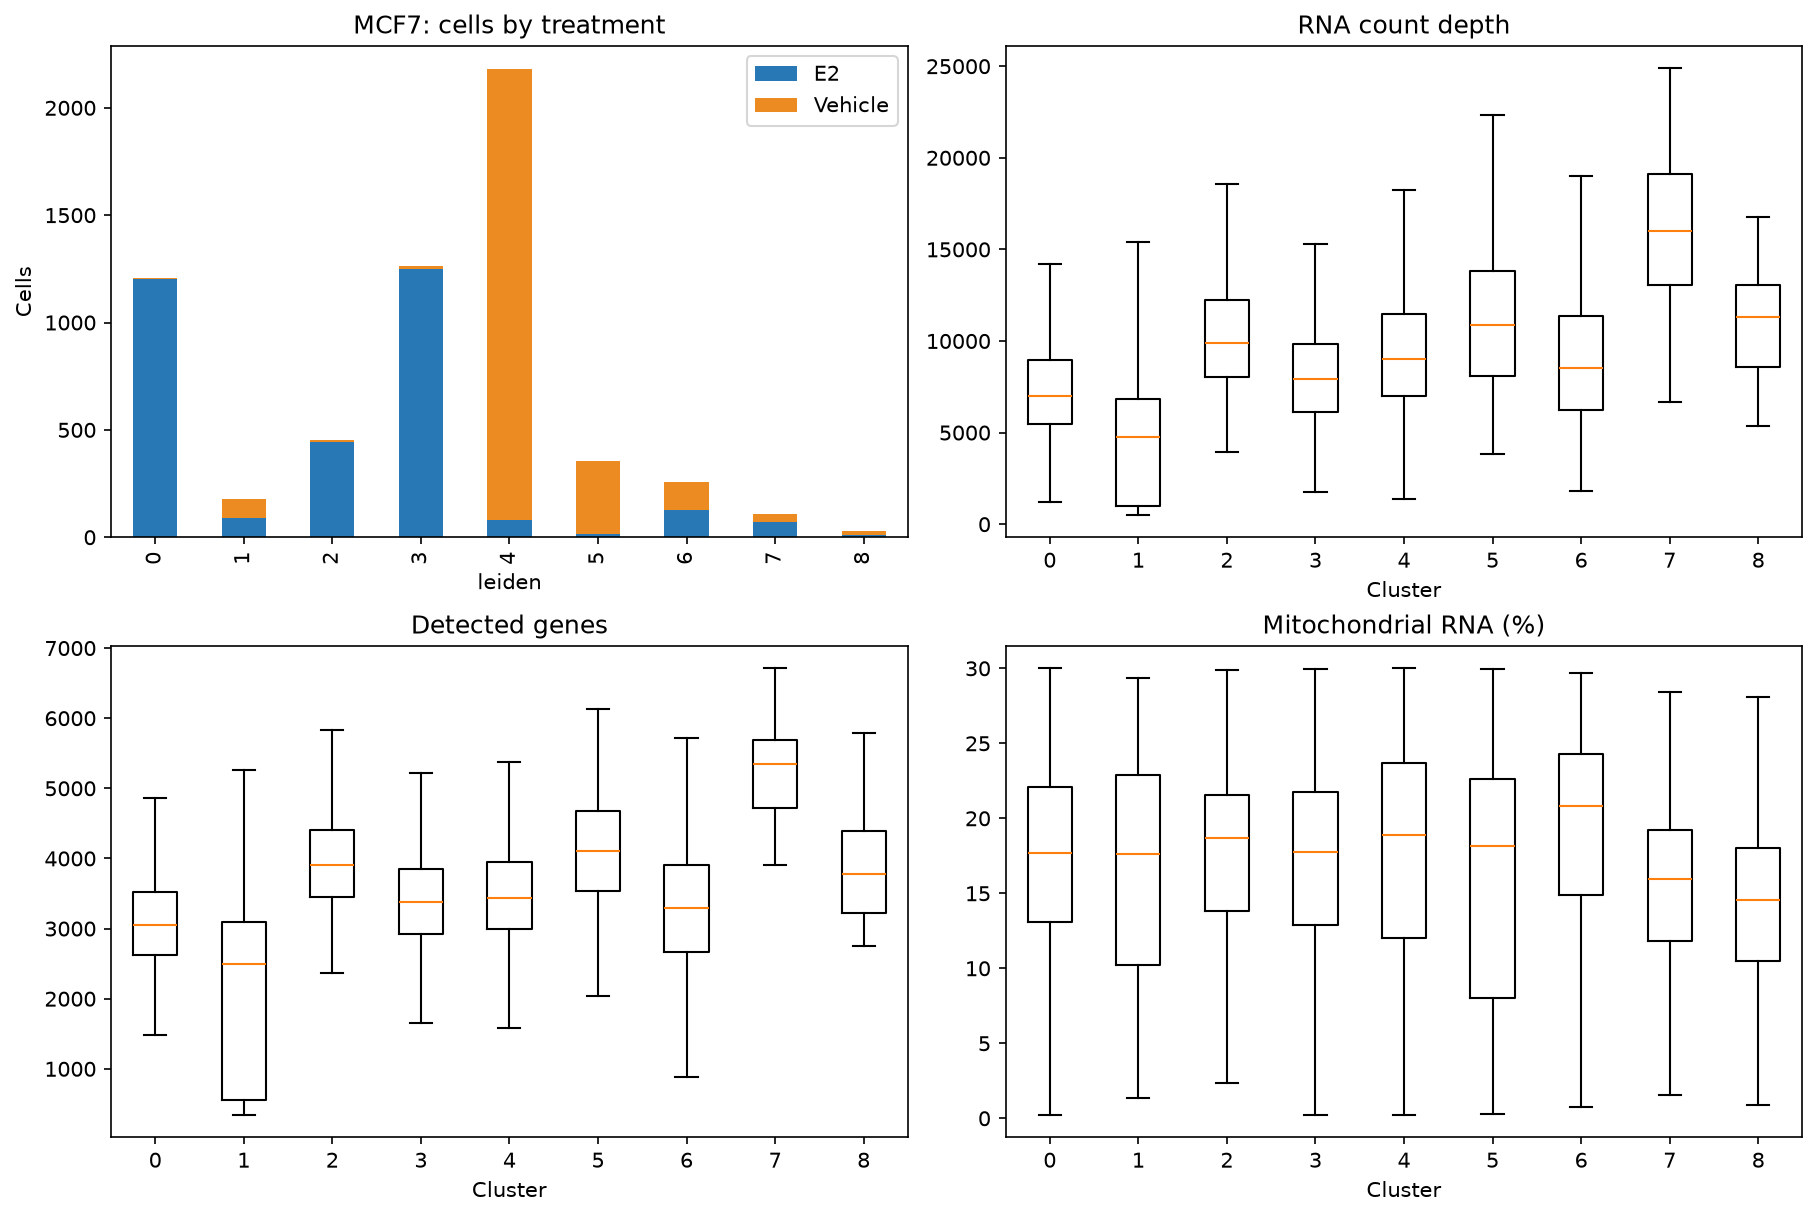

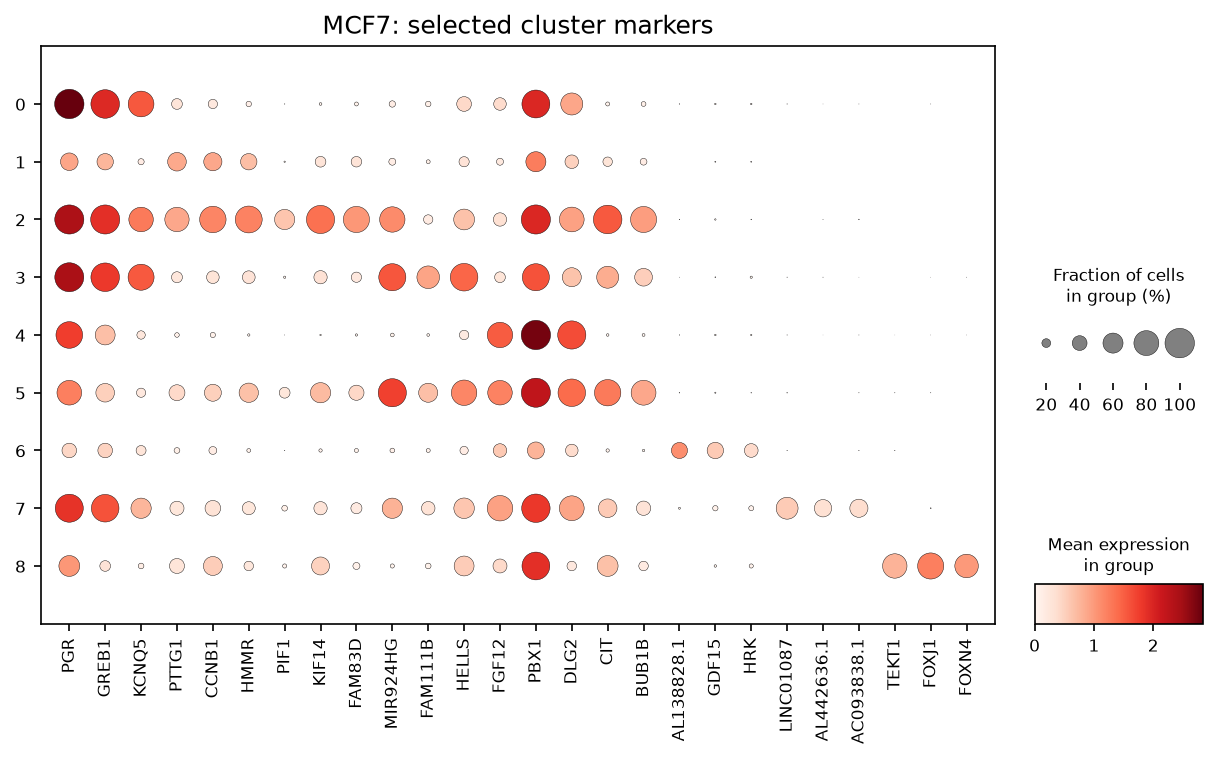

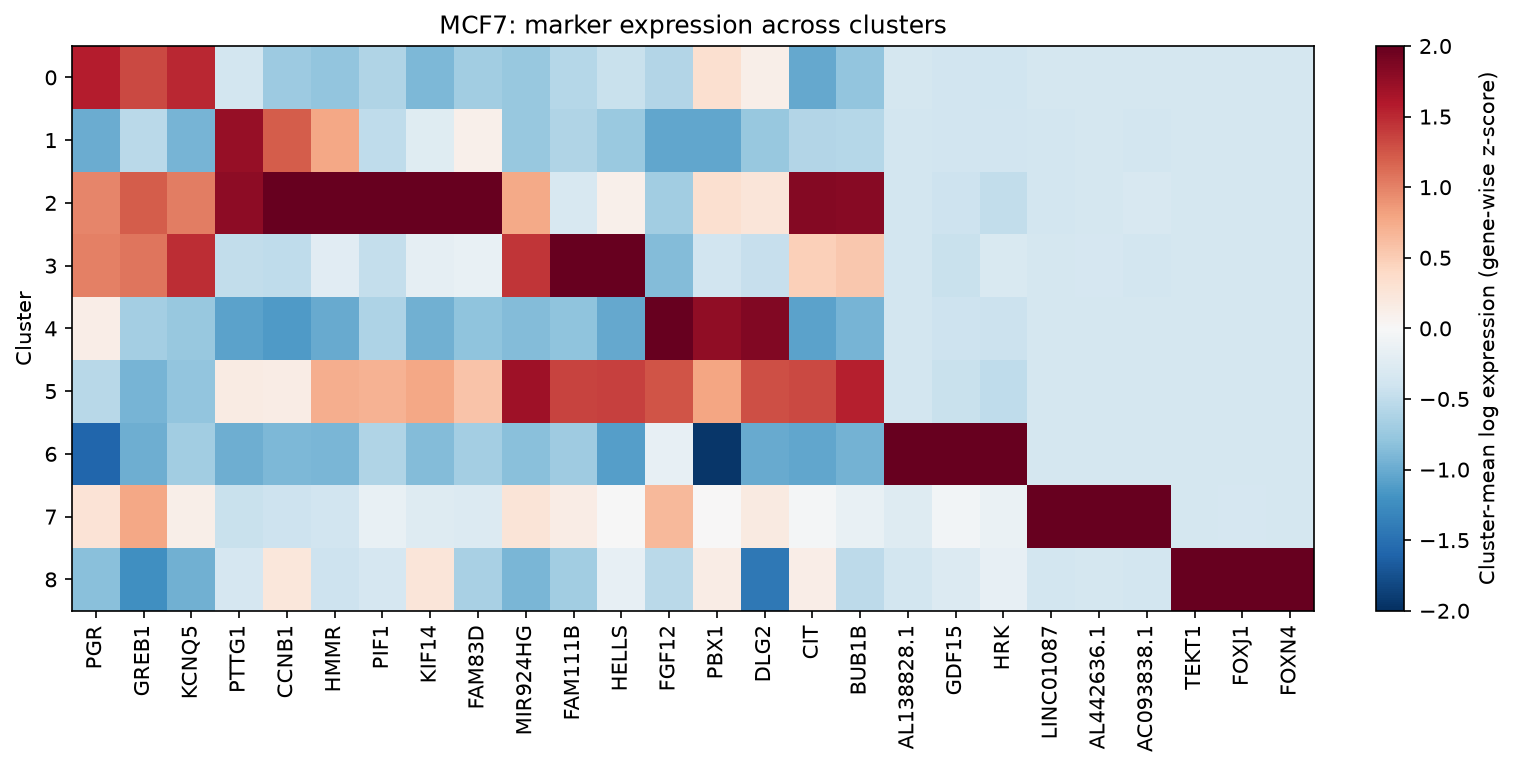

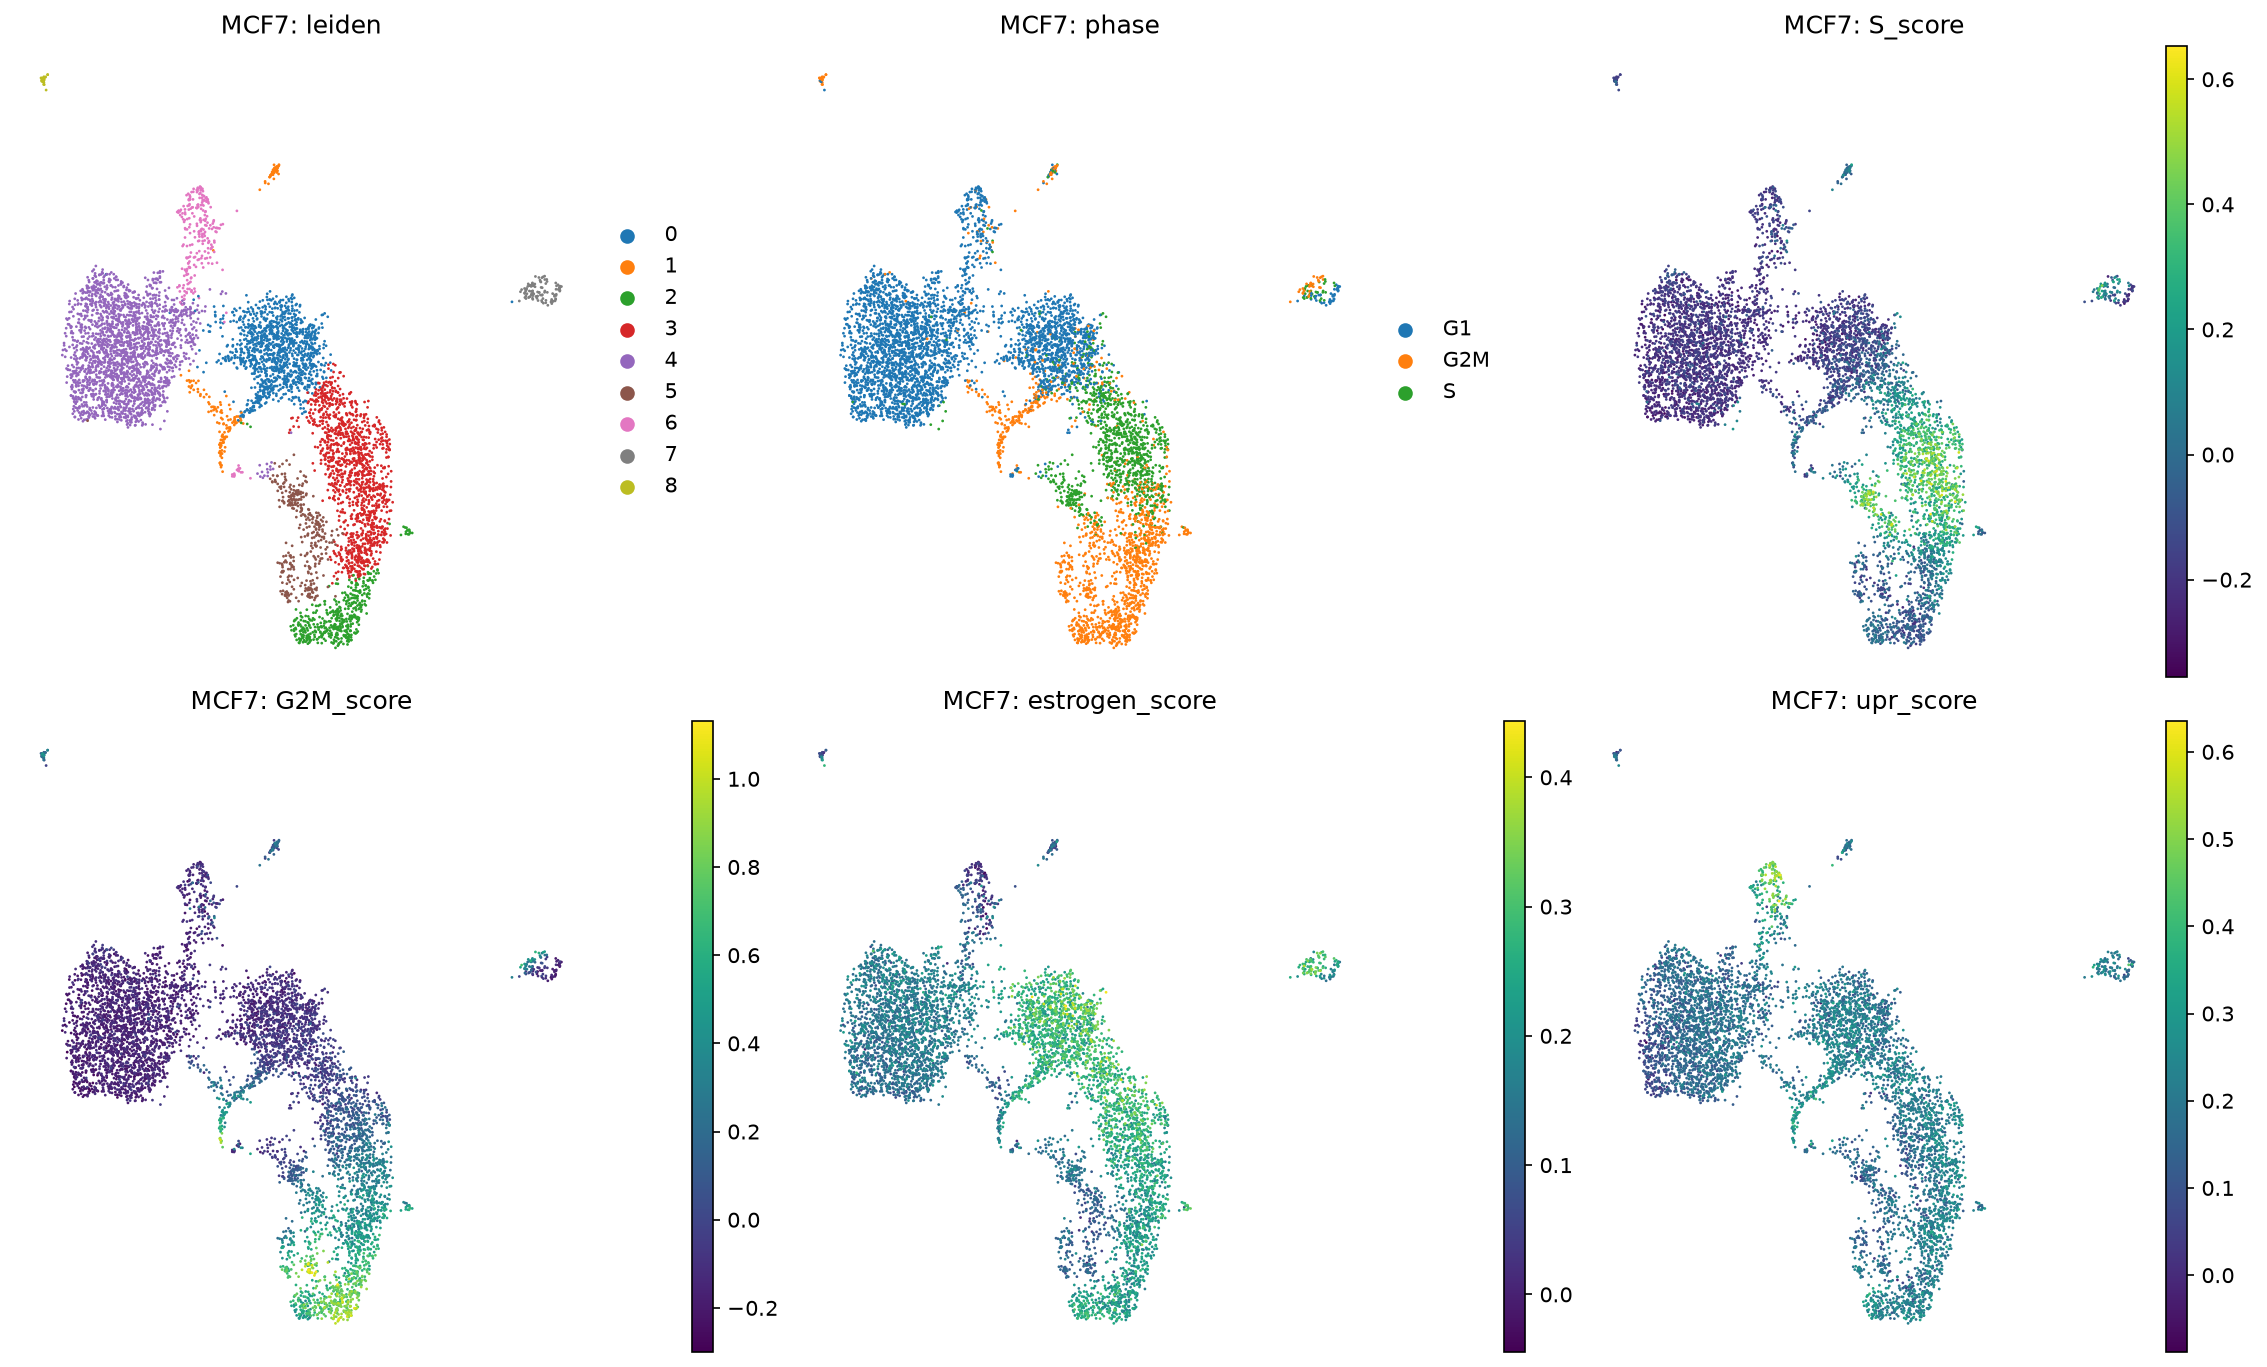

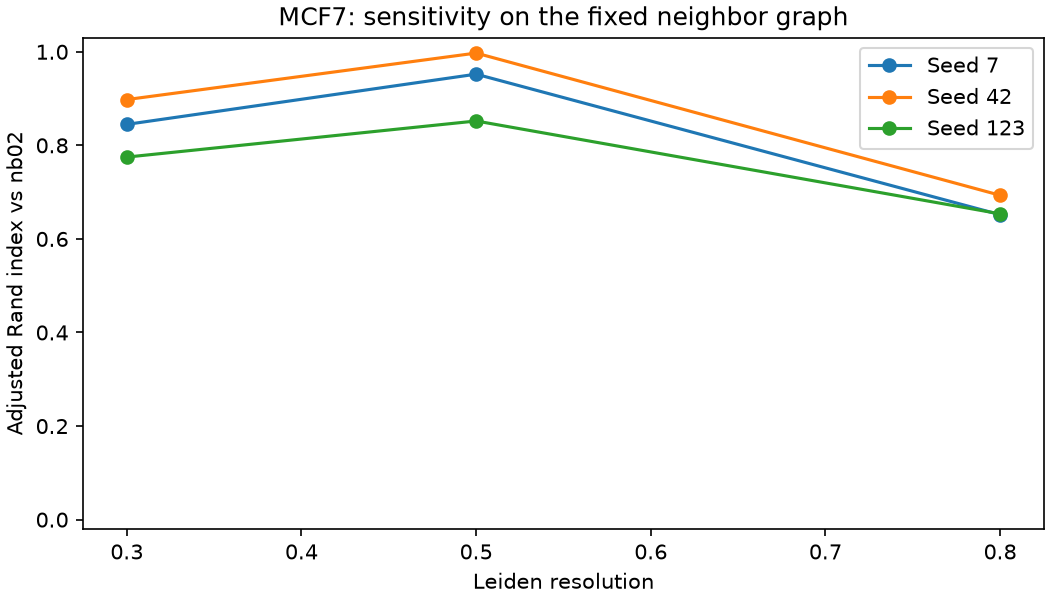

In [7]:
tables=BASE/'results/tables/nb03'
review=pd.read_csv(tables/'MCF7_cluster_review.tsv',sep='\t')
display(review)
display(pd.read_csv(tables/'MCF7_signature_coverage.tsv',sep='\t'))
display(pd.read_csv(tables/'MCF7_stability.tsv',sep='\t'))
for suffix in ('cluster_quality','marker_dotplot','marker_heatmap','state_umap','cluster_sensitivity'):
    display(Image(filename=str(BASE/'results/figures/nb03'/f'MCF7_{suffix}.png')))


## T47D: markers, quality, sensitivity and program scores

In [8]:
report['cell_lines']['T47D']=characterize_line(BASE,'T47D',CONFIG,REFERENCE)

T47D: load full retained-gene counts


normalizing counts per cell


    finished (0:00:00)


T47D: marker ranking across 26320 retained genes


ranking genes


...

computing score 'estrogen_score'


    finished (0:00:00)


computing score 'upr_score'


    finished (0:00:00)


{
  "n_cells": 6562,
  "n_genes_tested": 26320,
  "n_clusters": 8,
  "n_marker_rows": 210560,
  "n_filtered_markers": 8468,
  "signature_coverage": [
    {
      "program": "S_phase",
      "requested": 43,
      "present": 42,
      "fraction_present": 0.9767441860465116,
      "missing_genes": "MLF1IP"
    },
    {
      "program": "G2M_phase",
      "requested": 54,
      "present": 52,
      "fraction_present": 0.9629629629629629,
      "missing_genes": "FAM64A;HN1"
    },
    {
      "program": "HALLMARK_ESTROGEN_RESPONSE_EARLY",
      "requested": 200,
      "present": 200,
      "fraction_present": 1.0,
      "missing_genes": ""
    },
    {
      "program": "HALLMARK_UNFOLDED_PROTEIN_RESPONSE",
      "requested": 113,
      "present": 111,
      "fraction_present": 0.9823008849557522,
      "missing_genes": "IGFBP1;AC092881.1"
    }
  ],
  "source_sha256": "175350fa4536325fbe7dcc5e274c05b381261f8c0e24f9f3becd6e87b428f194",
  "input_unchanged": true,
  "cell_order_and_clusters_u

,leiden,median_rna_total_counts,median_rna_n_genes,median_rna_pct_counts_mt,n_cells,E2,Vehicle,fraction_E2,mean_S_score,mean_G2M_score,mean_estrogen_score,mean_upr_score,highest_relative_program,highest_relative_program_z,annotation_status,top_markers,min_best_jaccard
0,0,8929.0,3839.0,14.883640,570,556,14,0.975439,0.105316,0.004197,0.261215,0.208726,S_score,0.656335,unassigned; review markers and programs,TFF1;PLCL1;GREB1;FBXL7;HS6ST2,0.199010
1,1,7881.0,3495.0,10.882350,1924,1896,28,0.985447,0.076965,0.003749,0.293020,0.194935,estrogen_score,0.829255,unassigned; review markers and programs,NRIP1;GREB1;MYBL1;PKIB;PGR,0.419106
2,2,9700.0,3887.0,13.043480,1195,105,1090,0.087866,-0.083244,-0.095094,0.163516,0.155621,G2M_score,-0.398755,unassigned; review markers and programs,BCAS1;FGF13;CDKL5;COBLL1;HS6ST3,0.432432
3,3,6348.5,2987.5,4.991019,320,186,134,0.581250,-0.057095,-0.069062,0.168234,0.185039,upr_score,0.013825,unassigned; review markers and programs,ICAM1;EBI3;AC020651.2;PLSCR2;SNX31,0.368421
4,4,9590.5,3736.0,11.809600,1398,89,1309,0.063662,-0.082983,-0.147205,0.175804,0.152889,upr_score,-0.456741,unassigned; review markers and programs,NBEA;NPNT;ZNF804A;PRKG1;CCSER1,0.508778
5,5,2405.5,1398.5,12.790970,452,229,223,0.506637,-0.019939,0.145412,0.155389,0.231575,upr_score,0.694947,unassigned; review markers and programs,TENT5C;AP001160.1;CD83;SREBF2-AS1;CKS2,0.559913
6,6,11829.0,4396.0,13.730750,432,317,115,0.733796,0.018530,0.515746,0.260845,0.211212,G2M_score,2.290108,unassigned; review markers and programs,PIF1;KIF14;PRR11;CENPE;NEURL1B,0.109823
7,7,16196.0,5343.0,15.203690,271,187,84,0.690037,0.027531,0.050991,0.258060,0.218333,upr_score,0.501128,unassigned; review markers and programs,LINC01194;AP003900.1;LINC01876;ERVMER61-1;ZFPM2,1.000000


,program,requested,present,fraction_present,missing_genes
0,S_phase,43,42,0.976744,MLF1IP
1,G2M_phase,54,52,0.962963,FAM64A;HN1
2,HALLMARK_ESTROGEN_RESPONSE_EARLY,200,200,1.000000,NaN
3,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,113,111,0.982301,IGFBP1;AC092881.1


,run,resolution,seed,n_clusters,ARI_vs_nb02
0,r0.3_seed42,0.3,42,5,0.618072
1,r0.3_seed7,0.3,7,4,0.530695
2,r0.3_seed123,0.3,123,5,0.614101
3,r0.5_seed42,0.5,42,8,0.653358
4,r0.5_seed7,0.5,7,8,0.621292
5,r0.5_seed123,0.5,123,8,0.615864
6,r0.8_seed42,0.8,42,11,0.602220
7,r0.8_seed7,0.8,7,11,0.483876
8,r0.8_seed123,0.8,123,12,0.474836


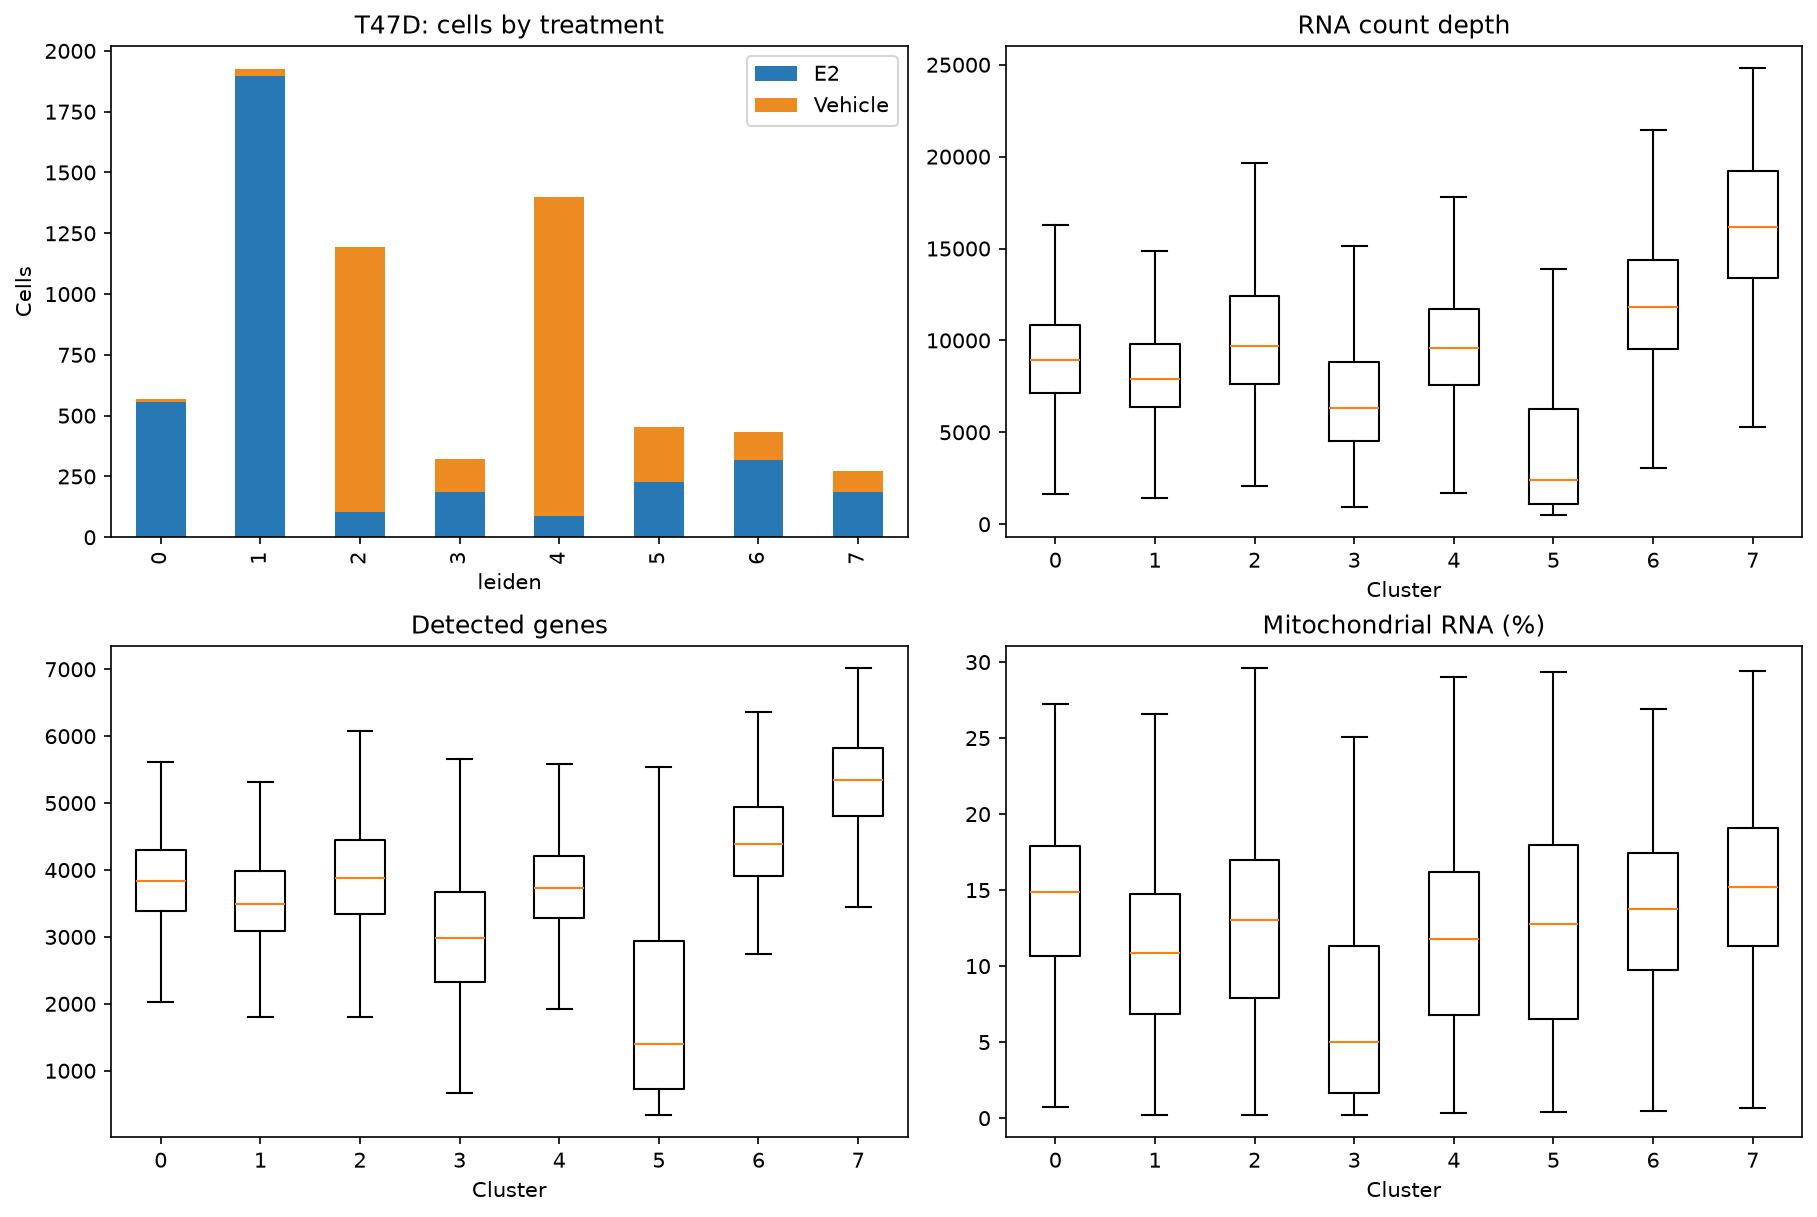

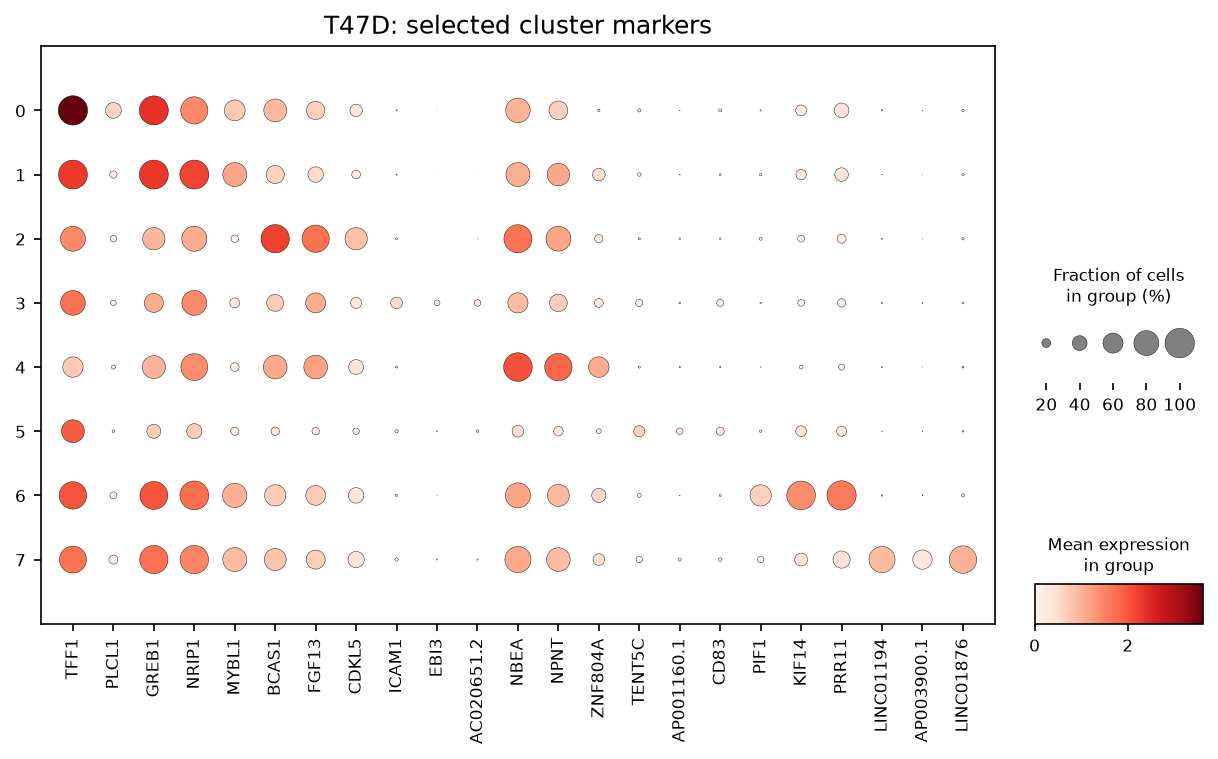

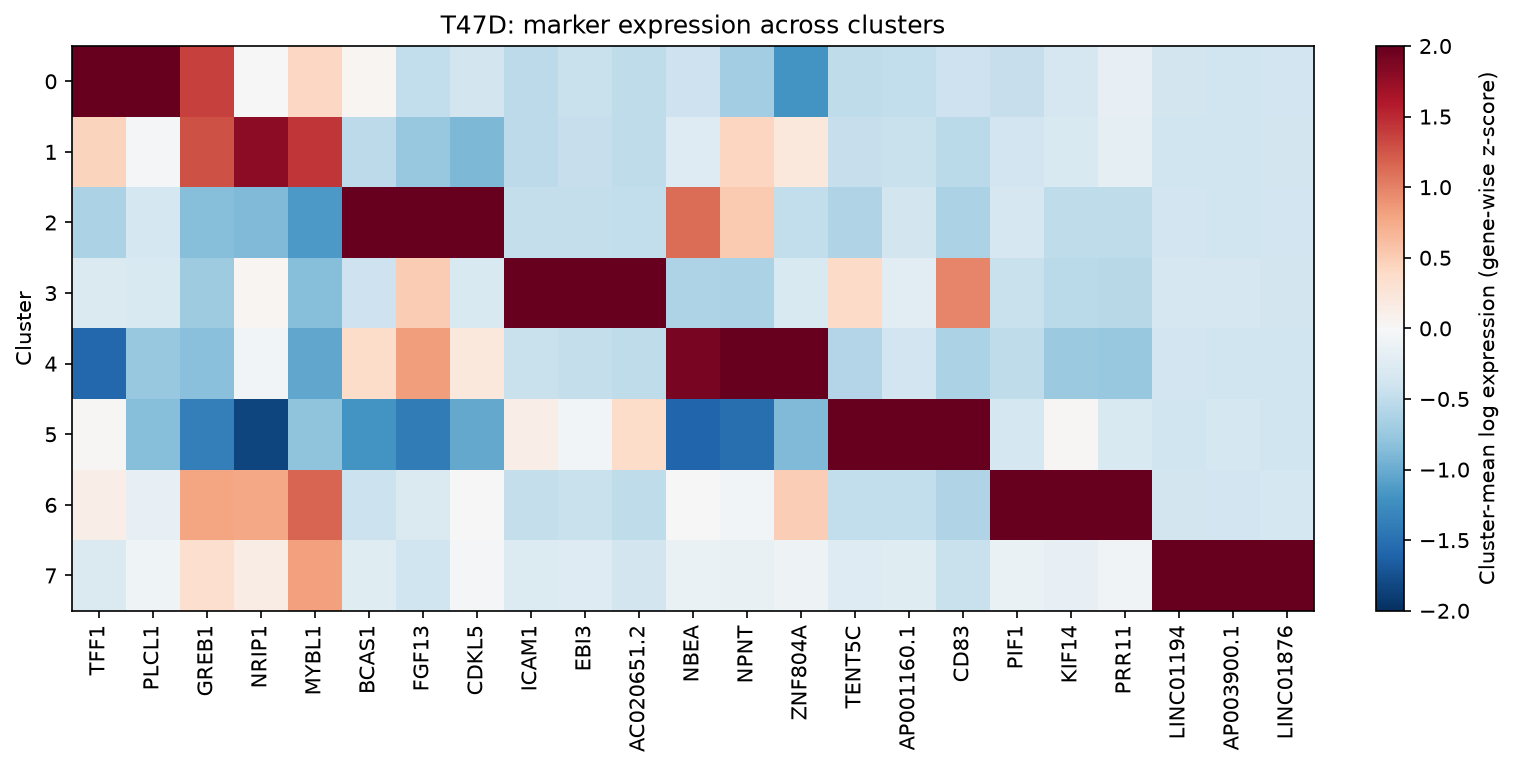

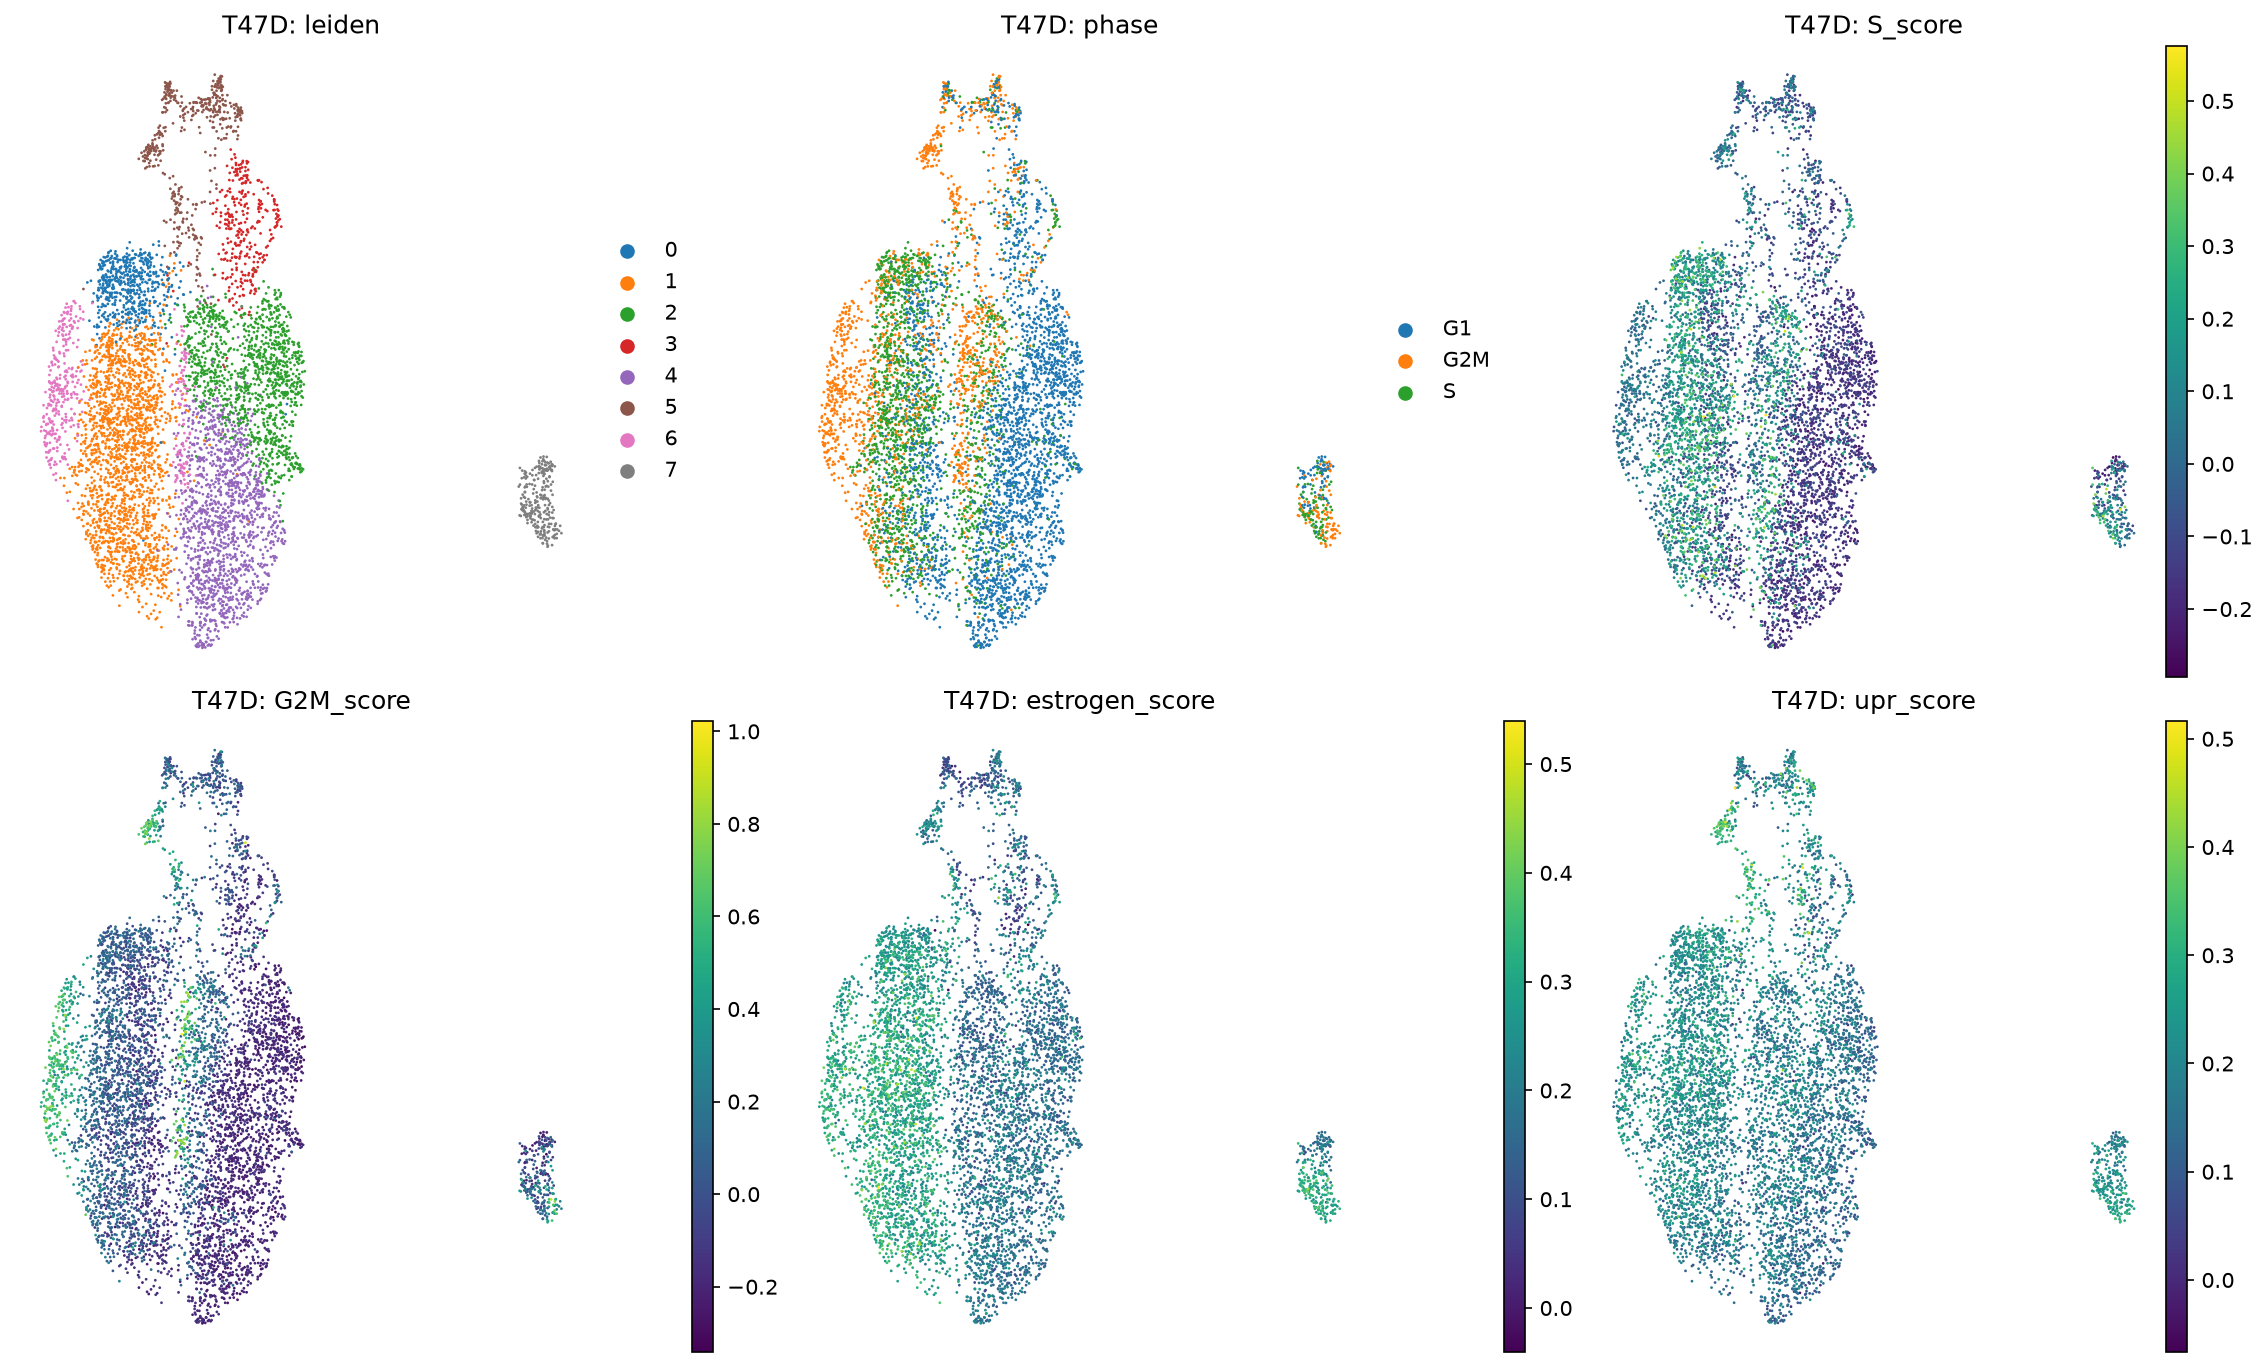

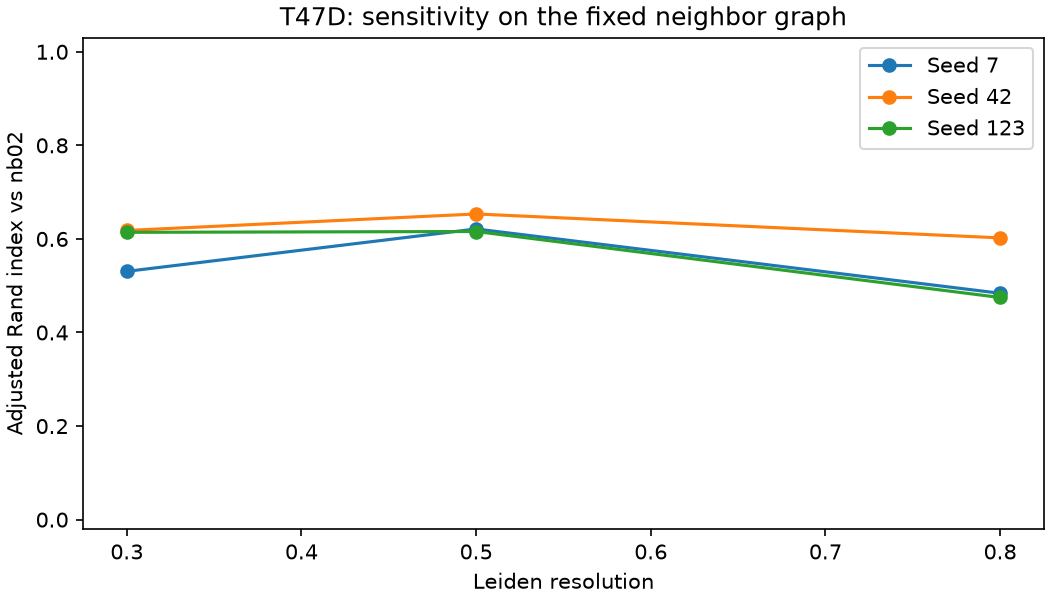

In [9]:
tables=BASE/'results/tables/nb03'
review=pd.read_csv(tables/'T47D_cluster_review.tsv',sep='\t')
display(review)
display(pd.read_csv(tables/'T47D_signature_coverage.tsv',sep='\t'))
display(pd.read_csv(tables/'T47D_stability.tsv',sep='\t'))
for suffix in ('cluster_quality','marker_dotplot','marker_heatmap','state_umap','cluster_sensitivity'):
    display(Image(filename=str(BASE/'results/figures/nb03'/f'T47D_{suffix}.png')))


## Save the validation and provenance record

In [10]:
(BASE/'results/tables/nb03/characterization_summary.json').write_text(json.dumps(report,indent=2)+'\n')
display(pd.DataFrame({k:{x:v[x] for x in ('n_cells','n_genes_tested','n_clusters','n_filtered_markers','input_unchanged')} for k,v in report['cell_lines'].items()}).T)


,n_cells,n_genes_tested,n_clusters,n_filtered_markers,input_unchanged
MCF7,6019,25105,9,12431,True
T47D,6562,26320,8,8468,True


## Initial interpretation of this run
These are tentative descriptions of the original nb02 clusters, not final cell-type labels.

| Cell line / cluster | Review hypothesis | Evidence in this run |
|---|---|---|
| MCF7 / 0 | Estrogen-response-associated expression | PGR, GREB1 and TFF1 among leading markers; relatively high estrogen score; 99.8% E2 cells |
| MCF7 / 2 | G2M-associated state | Highest cluster-mean G2M score; PIF1, KIF14 and HMMR among markers |
| MCF7 / 3 | S-phase-associated state | Highest cluster-mean S score; HELLS and ATAD2 among markers |
| MCF7 / 6 | UPR-associated state | Highest cluster-mean UPR score; GDF15 and DDIT3 among markers |
| T47D / 1 | Estrogen-response-associated expression | NRIP1, GREB1 and PGR among markers; highest cluster-mean estrogen score; 98.5% E2 cells |
| T47D / 6 | G2M-associated state | Highest cluster-mean G2M score; PIF1, KIF14 and CENPE among markers |
| T47D / 5 | Lower-depth cluster requiring QC review | Median 2,405.5 RNA counts and 1,398.5 detected genes; do not label it a biological state based only on its separation |

Treatment composition and cell-cycle variation both contribute to the observed structure.
These observations do not establish a causal treatment effect. MCF7 cluster 8 contains
only 27 cells and deserves separate scrutiny before annotation.

Replaying resolution 0.5 / seed 42 on the saved graph agrees with nb02 at ARI **0.9973
for MCF7** and **0.6534 for T47D**; a second repeat on the same saved graph is identical.
The reason for the difference from the original fit has not been established.
Additional resolution/seed results also show that exact boundaries are provisional,
especially in T47D. nb03 retains all original nb02 labels and makes no automatic
reassignment or cell exclusion. Review stability before downstream cluster-specific claims.


## Interpretation and next step
Read the marker dot plot and heatmap together with cluster QC, treatment fractions,
program scores and stability. A cluster with different E2/Vehicle proportions can
have treatment-associated markers without representing a distinct cell type.

S/G2M/phase are expression-based estimates; a G1 call is not evidence of quiescence.
UPR is one stress-related program, not a general stress diagnosis. Estrogen and UPR
signatures can overlap; scores are not mutually exclusive or directly comparable
between cell lines. Gene-set scores are not enrichment p-values.

The review table's highest relative program is the largest cluster mean after
standardizing each score within that cell line. It is a review cue, not an automatic
annotation. All clusters remain explicitly **unassigned** until marker and program
evidence supports a label. Small or sensitive clusters deserve extra review.

nb04 will perform E2-versus-Vehicle DEG and GSEA together, after checking biological
replicate availability. Do not treat cluster-marker significance as treatment-DE evidence.
